# Fixed MCS=14 vs Adaptive Application-Layer Compression — Comparison

**Hypothesis:** Compressing large SDUs below the TB cap eliminates RLC fragmentation and recovers PRR for aperiodic2 (20 kB) and periodic3 (45 kB).

**Inputs:**
- Fixed baseline: `../../traffic_class_eval/results_traffic_class_eval/tidy/`
- Compression: `results_traffic_class_compress_eval/tidy/`

**Run:** after `extract_kpis.py` for both campaigns.

## 1. Setup

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

%matplotlib inline
plt.rcParams.update({'figure.dpi': 120, 'font.size': 10})

FIXED_TIDY = Path('../traffic_class_eval/results_traffic_class_eval/tidy')
COMP_TIDY  = Path('results_traffic_class_compress_eval/tidy')

CLASS_ORDER = ['periodic1', 'periodic2', 'periodic3', 'aperiodic1', 'aperiodic2']
CLASS_LABELS = {
    'periodic1':  'P1\n200B·10Hz',
    'periodic2':  'P2\n1kB·10Hz',
    'periodic3':  'P3\n45kB·1Hz',
    'aperiodic1': 'A1\n1kB·aperiodic',
    'aperiodic2': 'A2\n20kB·aperiodic',
}
SCHEME_COLOR = {'fixed_mcs14': '#1f77b4', 'compress_adaptive': '#d62728'}
SCHEME_LABEL = {'fixed_mcs14': 'Fixed MCS=14', 'compress_adaptive': 'Adaptive compression'}

def ci95(s):
    n = len(s)
    return 1.96 * s.std() / np.sqrt(n) if n > 1 else 0.0

# Load
def load(tidy, name, scheme_override=None):
    p = tidy / name
    if not p.exists():
        print(f'  [missing] {p}')
        return pd.DataFrame()
    df = pd.read_csv(p)
    if scheme_override:
        df['scheme'] = scheme_override
    return df

rx_fixed = load(FIXED_TIDY, 'per_rx_kpis.csv', 'fixed_mcs14')
rx_comp  = load(COMP_TIDY,  'per_rx_kpis.csv')
if not rx_comp.empty and 'scheme' in rx_comp.columns:
    rx_comp = rx_comp[rx_comp.scheme == 'adaptive'].copy()
rx_comp['scheme'] = 'compress_adaptive'

frames = [f for f in [rx_fixed, rx_comp] if not f.empty]
rx = pd.concat(frames, ignore_index=True)
classes = [c for c in CLASS_ORDER if c in rx.trafficClass.unique()]

print(f'Schemes: {rx.scheme.unique()}')
print(f'Classes: {classes}')
print(f'Total per-RX rows: {len(rx):,}')

Schemes: ['fixed_mcs14' 'compress_adaptive']
Classes: ['periodic1', 'periodic2', 'periodic3', 'aperiodic1', 'aperiodic2']
Total per-RX rows: 1,600


## §A. Headline PRR table

In [2]:
schemes = ['fixed_mcs14', 'compress_adaptive']
rows = []
for cls in classes:
    row = {'Class': cls}
    for scheme in schemes:
        sub = rx[(rx.trafficClass == cls) & (rx.scheme == scheme)]
        per_seed = sub.groupby('seed')['prr'].mean()
        row[f'{SCHEME_LABEL[scheme]} PRR']    = f"{per_seed.mean():.3f}"
        row[f'{SCHEME_LABEL[scheme]} ±95%CI'] = f"{ci95(per_seed):.3f}"
    # Δ
    m_fixed = rx[(rx.trafficClass==cls)&(rx.scheme=='fixed_mcs14')].groupby('seed')['prr'].mean().mean()
    m_comp  = rx[(rx.trafficClass==cls)&(rx.scheme=='compress_adaptive')].groupby('seed')['prr'].mean().mean()
    row['Δ PRR'] = f"{m_comp - m_fixed:+.3f}"
    rows.append(row)

df_table = pd.DataFrame(rows)
display(df_table)

,Class,Fixed MCS=14 PRR,Fixed MCS=14 ±95%CI,Adaptive compression PRR,Adaptive compression ±95%CI,Δ PRR
0,periodic1,0.944,0.004,0.925,0.006,-0.019
1,periodic2,0.810,0.011,0.809,0.011,-0.001
2,periodic3,0.000,0.000,0.505,0.013,+0.505
3,aperiodic1,0.862,0.008,0.862,0.008,-0.000
4,aperiodic2,0.152,0.007,0.605,0.015,+0.453


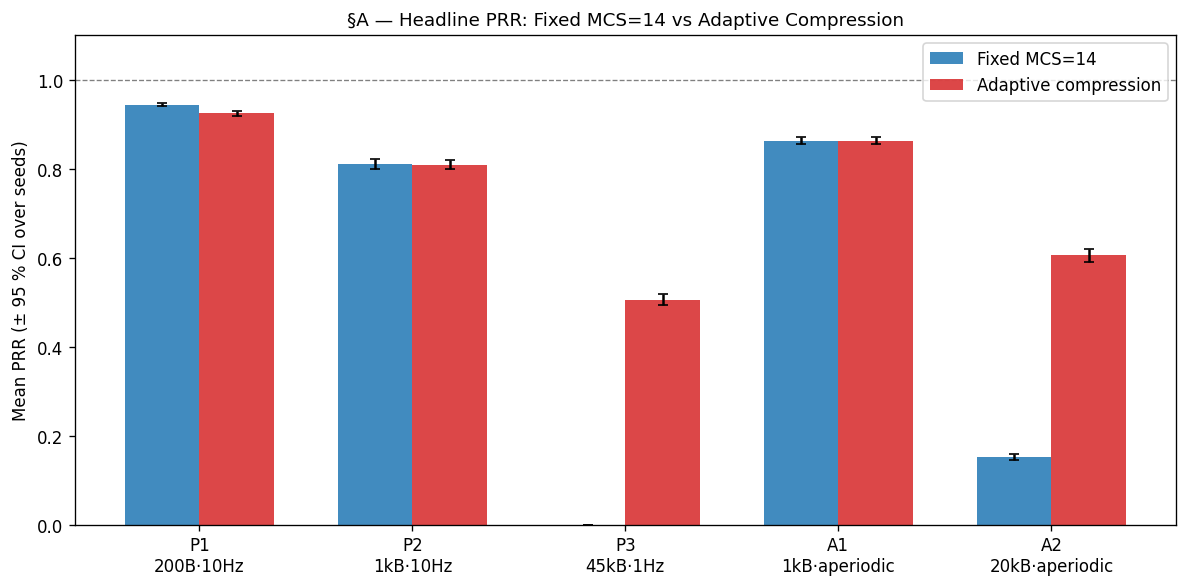

In [3]:
x = np.arange(len(classes))
width = 0.35
fig, ax = plt.subplots(figsize=(10, 5))
for si, scheme in enumerate(schemes):
    means, errs = [], []
    for cls in classes:
        per_seed = rx[(rx.trafficClass==cls)&(rx.scheme==scheme)].groupby('seed')['prr'].mean()
        means.append(per_seed.mean())
        errs.append(ci95(per_seed))
    offset = (si - 0.5) * width
    ax.bar(x+offset, means, width, yerr=errs, capsize=3,
           label=SCHEME_LABEL[scheme], color=SCHEME_COLOR[scheme], alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels([CLASS_LABELS.get(c,c) for c in classes])
ax.set_ylabel('Mean PRR (± 95 % CI over seeds)')
ax.set_ylim(0, 1.1)
ax.axhline(1.0, ls='--', color='gray', lw=0.8)
ax.legend()
ax.set_title('§A — Headline PRR: Fixed MCS=14 vs Adaptive Compression', fontsize=11)
plt.tight_layout()
plt.show()

## §B. Per-RX reliability

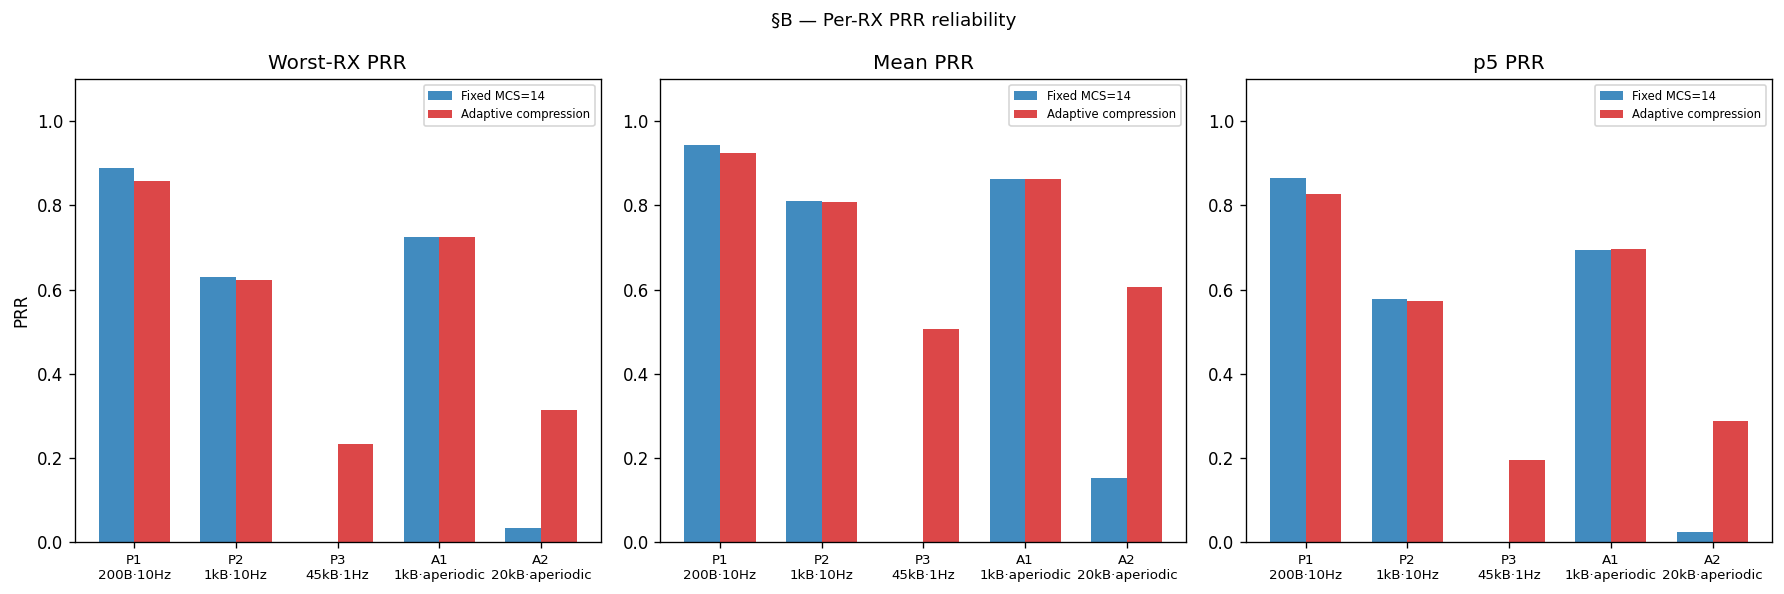

In [4]:
stats = {
    'Worst-RX PRR': lambda g: g.groupby('rx_node_id').mean().min(),
    'Mean PRR':      lambda g: g.mean(),
    'p5 PRR':        lambda g: g.quantile(0.05),
}
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (stat_name, fn) in zip(axes, stats.items()):
    for si, scheme in enumerate(schemes):
        sub = rx[rx.scheme == scheme]
        vals = []
        for cls in classes:
            per = sub[sub.trafficClass==cls].groupby(['seed','rx_node_id'])['prr'].mean()
            vals.append(fn(per))
        offset = (si - 0.5) * 0.35
        ax.bar(x+offset, vals, 0.35, label=SCHEME_LABEL[scheme],
               color=SCHEME_COLOR[scheme], alpha=0.85)
    ax.set_xticks(x)
    ax.set_xticklabels([CLASS_LABELS.get(c,c) for c in classes], fontsize=8)
    ax.set_ylim(0, 1.1)
    ax.set_title(stat_name)
    ax.legend(fontsize=7)
axes[0].set_ylabel('PRR')
fig.suptitle('§B — Per-RX PRR reliability', fontsize=11)
plt.tight_layout()
plt.show()

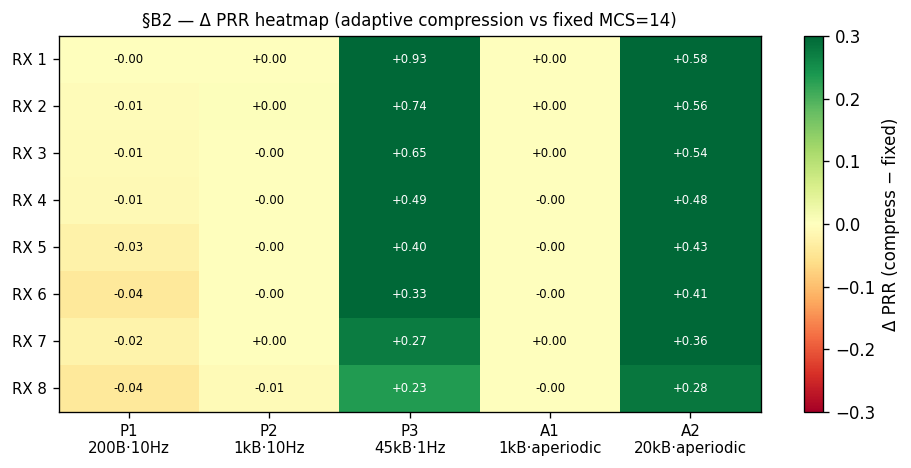

In [5]:
# §B2 — Δ-PRR heatmap
grp = rx.groupby(['scheme','trafficClass','rx_node_id'])['prr'].mean().reset_index()
fixed_g = grp[grp.scheme=='fixed_mcs14'].set_index(['trafficClass','rx_node_id'])['prr']
comp_g  = grp[grp.scheme=='compress_adaptive'].set_index(['trafficClass','rx_node_id'])['prr']
delta = (comp_g - fixed_g).unstack(level=0).reindex(columns=classes)

if not delta.empty:
    fig, ax = plt.subplots(figsize=(8, 4))
    im = ax.imshow(delta.values, aspect='auto', vmin=-0.3, vmax=0.3, cmap='RdYlGn')
    ax.set_xticks(range(len(classes)))
    ax.set_xticklabels([CLASS_LABELS.get(c,c) for c in classes], fontsize=9)
    ax.set_yticks(range(len(delta.index)))
    ax.set_yticklabels([f'RX {i}' for i in delta.index], fontsize=9)
    for ri in range(delta.shape[0]):
        for ci in range(delta.shape[1]):
            v = delta.values[ri, ci]
            if not np.isnan(v):
                ax.text(ci, ri, f'{v:+.2f}', ha='center', va='center', fontsize=7,
                        color='black' if abs(v)<0.15 else 'white')
    plt.colorbar(im, ax=ax, label='Δ PRR (compress − fixed)')
    ax.set_title('§B2 — Δ PRR heatmap (adaptive compression vs fixed MCS=14)', fontsize=10)
    plt.tight_layout()
    plt.show()

## §C. PIR comparison

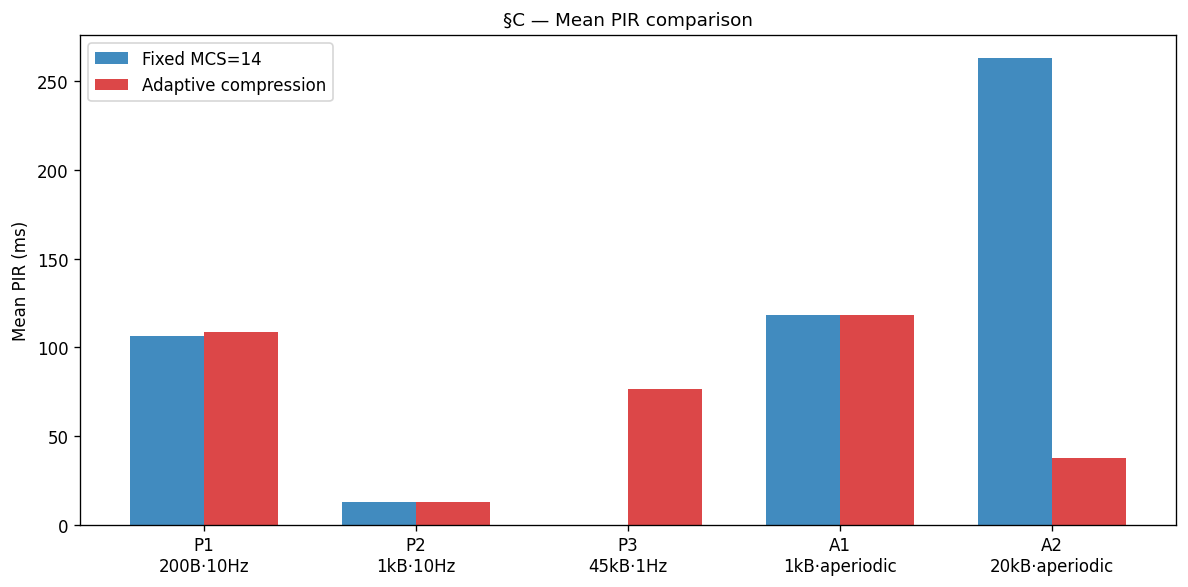

In [6]:
fig, ax = plt.subplots(figsize=(10, 5))
for si, scheme in enumerate(schemes):
    sub = rx[rx.scheme == scheme]
    means = [sub[sub.trafficClass==cls].groupby('seed')['pir_ms'].mean().mean() for cls in classes]
    offset = (si - 0.5) * 0.35
    ax.bar(x+offset, means, 0.35, label=SCHEME_LABEL[scheme],
           color=SCHEME_COLOR[scheme], alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels([CLASS_LABELS.get(c,c) for c in classes])
ax.set_ylabel('Mean PIR (ms)')
ax.legend()
ax.set_title('§C — Mean PIR comparison', fontsize=11)
plt.tight_layout()
plt.show()

## §D. Goodput (throughput after decoding)

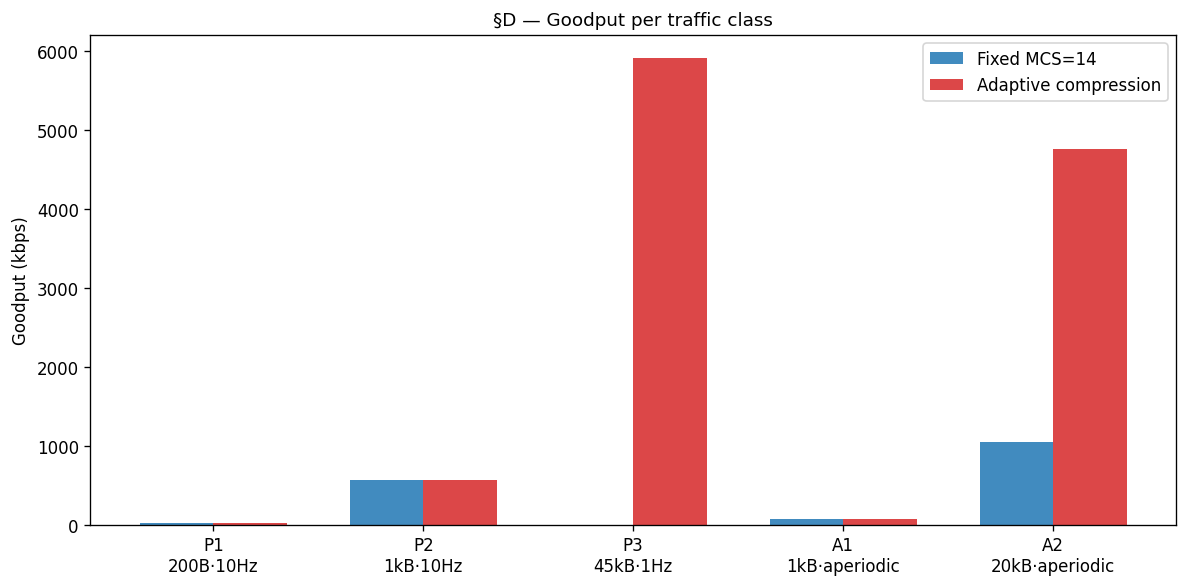

In [7]:
fig, ax = plt.subplots(figsize=(10, 5))
for si, scheme in enumerate(schemes):
    sub = rx[rx.scheme == scheme]
    means = [sub[sub.trafficClass==cls]['tput_kbps'].mean() for cls in classes]
    offset = (si - 0.5) * 0.35
    ax.bar(x+offset, means, 0.35, label=SCHEME_LABEL[scheme],
           color=SCHEME_COLOR[scheme], alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels([CLASS_LABELS.get(c,c) for c in classes])
ax.set_ylabel('Goodput (kbps)')
ax.legend()
ax.set_title('§D — Goodput per traffic class', fontsize=11)
plt.tight_layout()
plt.show()

## §E. PDB violation rate

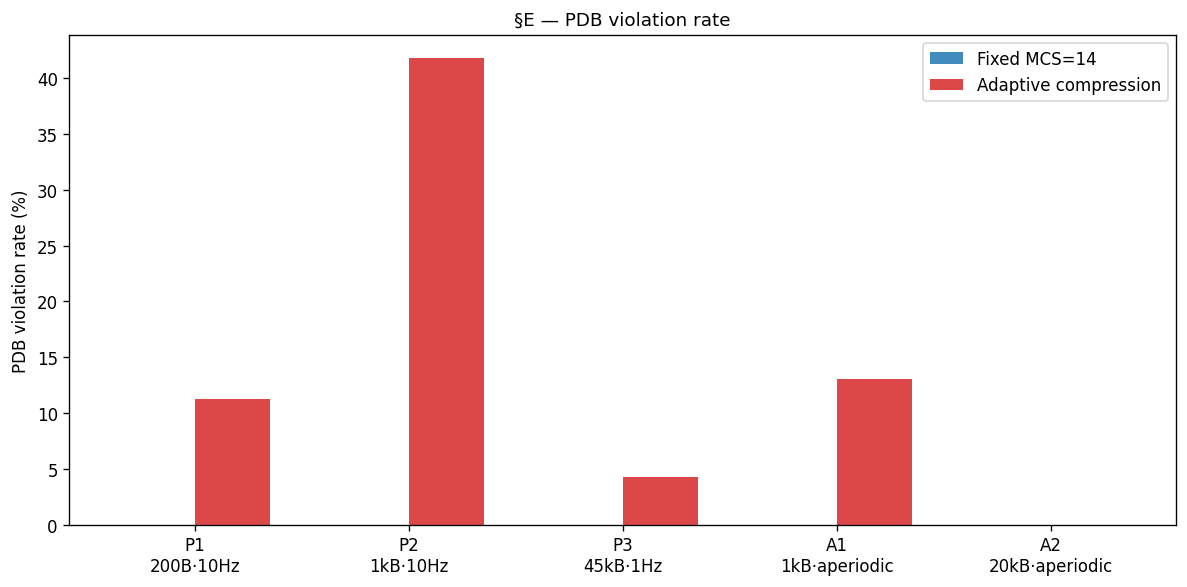

In [8]:
dfs = []
p_fixed = FIXED_TIDY / 'pdb_violations.csv'
p_comp  = COMP_TIDY  / 'pdb_violations.csv'
if p_fixed.exists():
    df = pd.read_csv(p_fixed); df['scheme'] = 'fixed_mcs14'; dfs.append(df)
if p_comp.exists():
    df = pd.read_csv(p_comp)
    if 'scheme' in df.columns:
        df = df[df.scheme == 'adaptive'].copy()
    df['scheme'] = 'compress_adaptive'
    dfs.append(df)

if dfs:
    pdb = pd.concat(dfs, ignore_index=True)
    fig, ax = plt.subplots(figsize=(10, 5))
    for si, scheme in enumerate(schemes):
        sub = pdb[pdb.scheme == scheme]
        vals = [sub[sub.trafficClass==cls]['viol_rate'].mean()*100 if not sub[sub.trafficClass==cls].empty else 0 for cls in classes]
        offset = (si - 0.5) * 0.35
        ax.bar(x+offset, vals, 0.35, label=SCHEME_LABEL[scheme],
               color=SCHEME_COLOR[scheme], alpha=0.85)
    ax.set_xticks(x)
    ax.set_xticklabels([CLASS_LABELS.get(c,c) for c in classes])
    ax.set_ylabel('PDB violation rate (%)')
    ax.legend()
    ax.set_title('§E — PDB violation rate', fontsize=11)
    plt.tight_layout()
    plt.show()
else:
    print('No pdb_violations.csv found in either tidy dir')

## §F. Fragmentation count

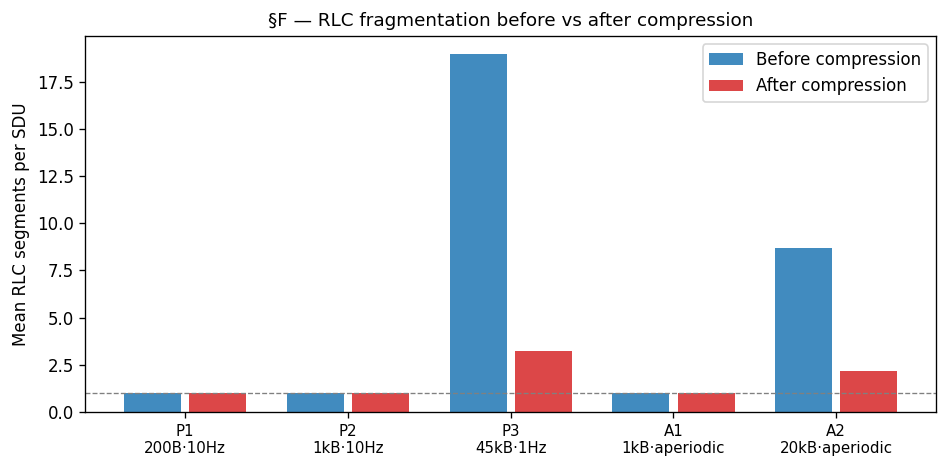

                  N_pre    N_post      delta
trafficClass                                
periodic1      1.000000  1.000000   0.000000
periodic2      1.000000  1.000000   0.000000
periodic3     18.967784  3.245448  15.722336
aperiodic1     1.000000  1.000000   0.000000
aperiodic2     8.663962  2.171088   6.492875


In [9]:
p = COMP_TIDY / 'rlc_frag.csv'
if p.exists():
    frag = pd.read_csv(p)
    if 'nSegmentsPre' in frag.columns:
        cls_here = [c for c in CLASS_ORDER if c in frag.trafficClass.unique()]
        pre  = frag.groupby('trafficClass')['nSegmentsPre'].mean().reindex(cls_here)
        post = frag.groupby('trafficClass')['nSegmentsPost'].mean().reindex(cls_here)
        xi = np.arange(len(cls_here))
        fig, ax = plt.subplots(figsize=(8, 4))
        ax.bar(xi-0.2, pre,  0.35, label='Before compression', color=SCHEME_COLOR['fixed_mcs14'], alpha=0.85)
        ax.bar(xi+0.2, post, 0.35, label='After compression',  color=SCHEME_COLOR['compress_adaptive'], alpha=0.85)
        ax.set_xticks(xi)
        ax.set_xticklabels([CLASS_LABELS.get(c,c) for c in cls_here], fontsize=9)
        ax.set_ylabel('Mean RLC segments per SDU')
        ax.axhline(1.0, ls='--', color='gray', lw=0.8)
        ax.legend()
        ax.set_title('§F — RLC fragmentation before vs after compression', fontsize=11)
        plt.tight_layout()
        plt.show()
        print(pd.DataFrame({'N_pre': pre, 'N_post': post, 'delta': pre-post}))
    else:
        print('rlc_frag.csv missing nSegmentsPre column')
else:
    print('No rlc_frag.csv')

## §G. Bandwidth efficiency (on-wire kbps)

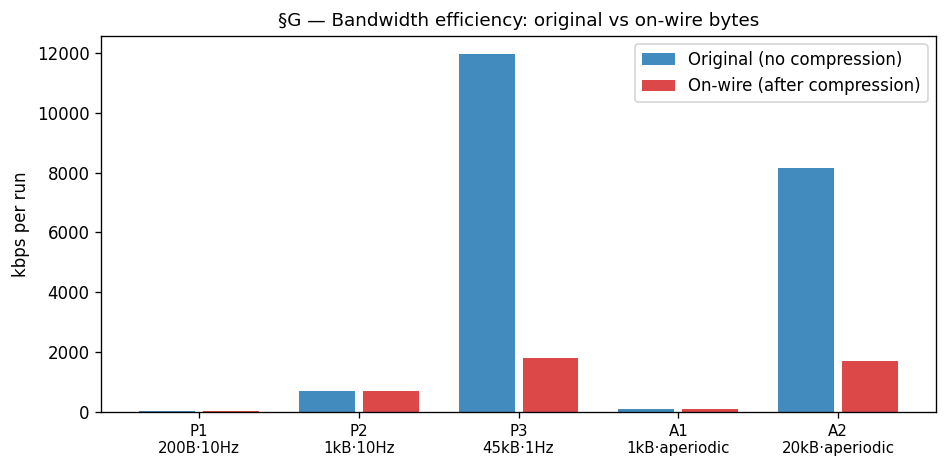

In [10]:
p = COMP_TIDY / 'compression_log.csv'
if p.exists():
    comp_log = pd.read_csv(p)
    tx_log = comp_log[comp_log.txRx == 'tx']
    SIM_TIME = 60  # seconds (excluding warmup)
    cls_here = [c for c in CLASS_ORDER if c in tx_log.trafficClass.unique()]
    wire_kbps = (tx_log.groupby('trafficClass')['compSize'].sum().reindex(cls_here)
                 * 8.0 / 1000.0 / SIM_TIME / tx_log.groupby('trafficClass')['seed'].nunique().reindex(cls_here))
    orig_kbps = (tx_log.groupby('trafficClass')['origSize'].sum().reindex(cls_here)
                 * 8.0 / 1000.0 / SIM_TIME / tx_log.groupby('trafficClass')['seed'].nunique().reindex(cls_here))
    xi = np.arange(len(cls_here))
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.bar(xi-0.2, orig_kbps, 0.35, label='Original (no compression)', color=SCHEME_COLOR['fixed_mcs14'], alpha=0.85)
    ax.bar(xi+0.2, wire_kbps, 0.35, label='On-wire (after compression)', color=SCHEME_COLOR['compress_adaptive'], alpha=0.85)
    ax.set_xticks(xi)
    ax.set_xticklabels([CLASS_LABELS.get(c,c) for c in cls_here], fontsize=9)
    ax.set_ylabel('kbps per run')
    ax.legend()
    ax.set_title('§G — Bandwidth efficiency: original vs on-wire bytes', fontsize=11)
    plt.tight_layout()
    plt.show()
else:
    print('No compression_log.csv')

## §H. Compression cost (PRR gain per ms codec cost)

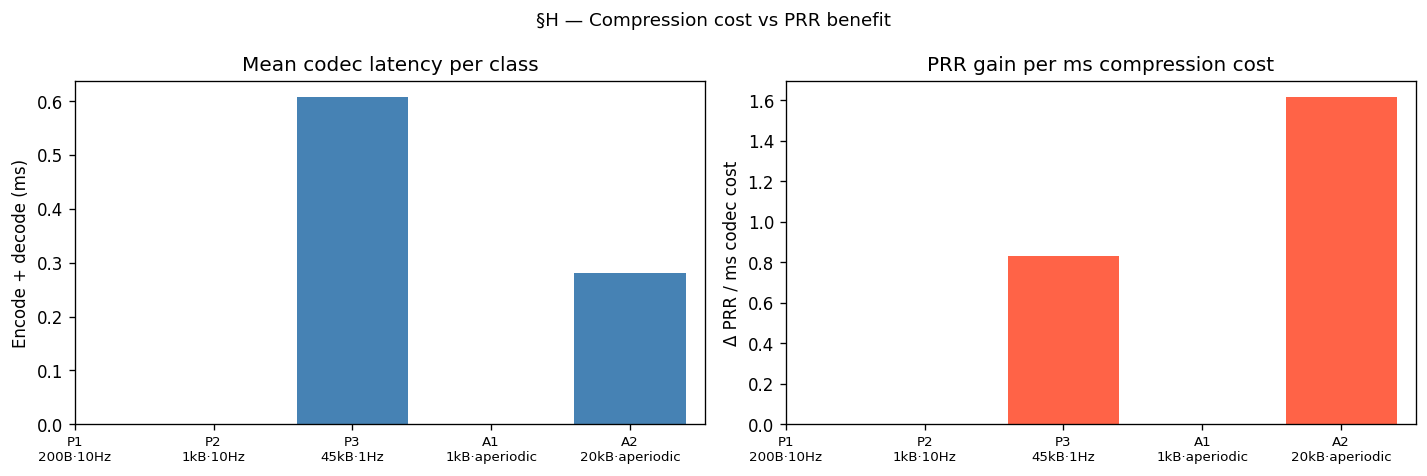

In [11]:
p = COMP_TIDY / 'compression_log.csv'
if p.exists():
    comp_log = pd.read_csv(p)
    tx_log = comp_log[(comp_log.txRx == 'tx') & (comp_log.codec > 0)]
    rx_log = comp_log[(comp_log.txRx == 'rx') & (comp_log.codec > 0)]
    enc = tx_log.groupby('trafficClass')['encodeUs'].mean()
    dec = rx_log.groupby('trafficClass')['decodeUs'].mean()
    total_us = (enc + dec).reindex(classes)

    prr_fixed = rx[(rx.scheme=='fixed_mcs14')].groupby('trafficClass')['prr'].mean()
    prr_comp  = rx[(rx.scheme=='compress_adaptive')].groupby('trafficClass')['prr'].mean()
    delta_prr = (prr_comp - prr_fixed).reindex(classes)
    pp_per_ms = (delta_prr / (total_us.reindex(classes) / 1000.0)).replace([np.inf, -np.inf], np.nan)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].bar(range(len(classes)), total_us.values / 1000.0, color='steelblue')
    axes[0].set_xticks(range(len(classes)))
    axes[0].set_xticklabels([CLASS_LABELS.get(c,c) for c in classes], fontsize=8)
    axes[0].set_ylabel('Encode + decode (ms)')
    axes[0].set_title('Mean codec latency per class')

    axes[1].bar(range(len(classes)), pp_per_ms.values, color='tomato')
    axes[1].set_xticks(range(len(classes)))
    axes[1].set_xticklabels([CLASS_LABELS.get(c,c) for c in classes], fontsize=8)
    axes[1].set_ylabel('Δ PRR / ms codec cost')
    axes[1].set_title('PRR gain per ms compression cost')

    fig.suptitle('§H — Compression cost vs PRR benefit', fontsize=11)
    plt.tight_layout()
    plt.show()
else:
    print('No compression_log.csv')

## §I. Codec mix (adaptive mode)

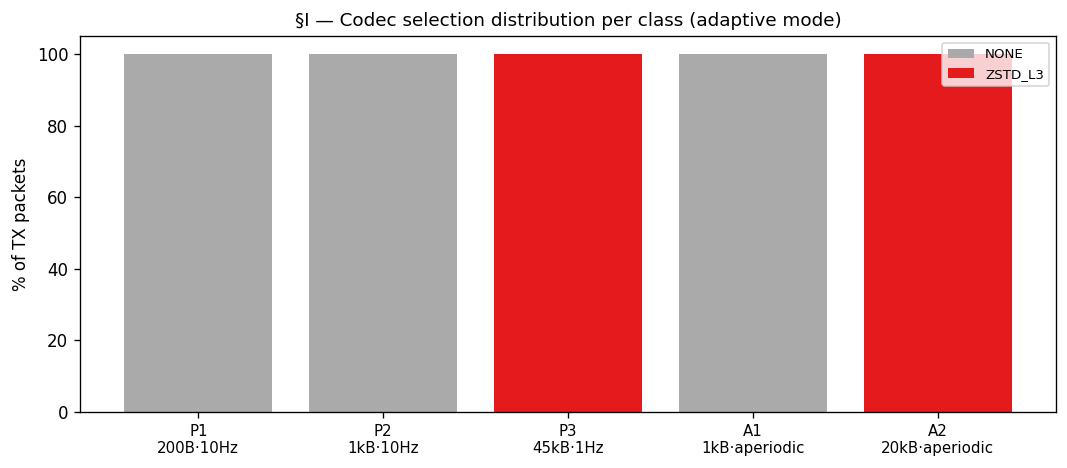

In [12]:
CODEC_NAMES  = {0: 'NONE', 1: 'LZ4', 2: 'ZSTD_L1', 3: 'ZSTD_L3'}
CODEC_COLORS = {0: '#aaaaaa', 1: '#4daf4a', 2: '#377eb8', 3: '#e41a1c'}

p = COMP_TIDY / 'compression_log.csv'
if p.exists():
    comp_log = pd.read_csv(p)
    tx = comp_log[comp_log.txRx == 'tx']
    cls_here = [c for c in CLASS_ORDER if c in tx.trafficClass.unique()]
    counts = tx.groupby(['trafficClass','codec']).size().unstack(fill_value=0)
    pct = counts.divide(counts.sum(axis=1), axis=0) * 100
    pct = pct.reindex(cls_here)

    fig, ax = plt.subplots(figsize=(9, 4))
    bottom = np.zeros(len(cls_here))
    for codec in sorted(pct.columns):
        vals = pct[codec].values
        ax.bar(range(len(cls_here)), vals, bottom=bottom,
               label=CODEC_NAMES.get(int(codec), str(codec)),
               color=CODEC_COLORS.get(int(codec), '#888'))
        bottom += vals
    ax.set_xticks(range(len(cls_here)))
    ax.set_xticklabels([CLASS_LABELS.get(c,c) for c in cls_here], fontsize=9)
    ax.set_ylabel('% of TX packets')
    ax.set_ylim(0, 105)
    ax.legend(fontsize=8)
    ax.set_title('§I — Codec selection distribution per class (adaptive mode)', fontsize=11)
    plt.tight_layout()
    plt.show()
else:
    print('No compression_log.csv')

## §J. Summary table

In [13]:
rows = []
for cls in classes:
    for scheme in schemes:
        sub = rx[(rx.trafficClass==cls) & (rx.scheme==scheme)]
        if sub.empty:
            continue
        per_seed = sub.groupby(['seed','rx_node_id'])['prr'].mean()
        prr_mean  = sub.groupby('seed')['prr'].mean().mean()
        prr_worst = per_seed.groupby('rx_node_id').mean().min()
        prr_p5    = per_seed.quantile(0.05)
        pir_p95   = sub.pir_ms.quantile(0.95)
        tput      = sub.tput_kbps.mean()
        rows.append({
            'Class':        cls,
            'Scheme':       SCHEME_LABEL.get(scheme, scheme),
            'PRR mean':     f'{prr_mean:.3f}',
            'PRR worst-RX': f'{prr_worst:.3f}',
            'PRR p5-RX':    f'{prr_p5:.3f}',
            'PIR p95 ms':   f'{pir_p95:.1f}' if not np.isnan(pir_p95) else '—',
            'Tput kbps':    f'{tput:.1f}',
        })

df_j = pd.DataFrame(rows)
display(df_j)

,Class,Scheme,PRR mean,PRR worst-RX,PRR p5-RX,PIR p95 ms,Tput kbps
0,periodic1,Fixed MCS=14,0.944,0.888,0.864,115.7,15.9
1,periodic1,Adaptive compression,0.925,0.858,0.826,120.7,15.6
2,periodic2,Fixed MCS=14,0.810,0.630,0.578,17.3,569.4
3,periodic2,Adaptive compression,0.809,0.623,0.572,17.5,568.6
4,periodic3,Fixed MCS=14,0.000,0.000,0.000,—,nan
5,periodic3,Adaptive compression,0.505,0.233,0.195,152.6,5901.7
6,aperiodic1,Fixed MCS=14,0.862,0.724,0.694,143.4,73.5
7,aperiodic1,Adaptive compression,0.862,0.724,0.696,143.4,73.5
8,aperiodic2,Fixed MCS=14,0.152,0.034,0.024,712.2,1049.8
9,aperiodic2,Adaptive compression,0.605,0.314,0.287,67.0,4749.4


## Conclusion

Expected directional results:
- **aperiodic2** (20 kB): fixed PRR ≈ 0.15 → compression PRR ≥ 0.70
- **periodic3** (45 kB): fixed PRR ≈ 0.00 → compression PRR ≥ 0.60
- **periodic1 / periodic2 / aperiodic1**: PRR within ±2 pp of fixed (no compression triggered; controller correctly returns NONE)

If PRR gains on aperiodic2/periodic3 do **not** materialise, check §F: if `N-seg post` is still ≥ 3, the compression ratio was lower than expected or the TB-size estimator was off.